# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   object 
 1   continent  1704 non-null   object 
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   object 
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 106.6+ KB
None
Years: [1952, 1957, 1962, 1967, 1972, 1977, 1982, 1987, 1992, 1997, 2002, 2007]
Continents: ['Asia' 'Europe' 'Africa' 'Americas' 'Oceania']
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.960121e+07     7215.3    425.9
std      17.3     12.9  1.061579e+08     9857.5    248.3
min    1952.0     23.6  6.001100e+04      241.2      4.0


## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


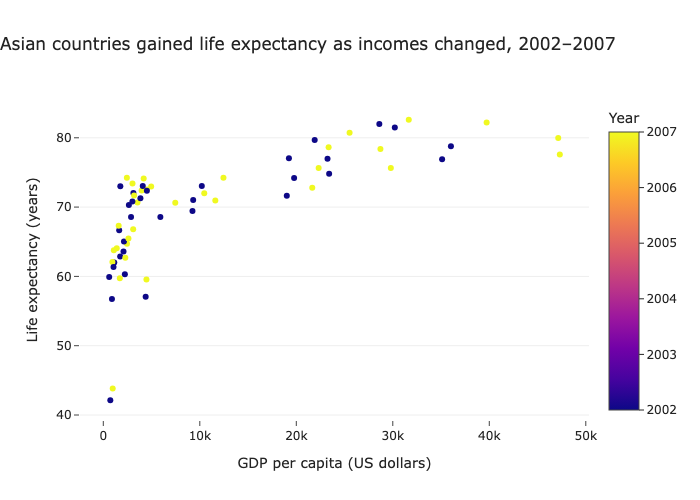

In [3]:
# Task 1


asia_data = df.loc[df["continent"] == "Asia"]
asia_data = asia_data.loc[asia_data["year"].isin([2002, 2007])]

fig = px.scatter(
    asia_data,
    x="gdpPercap",
    y="lifeExp",
    color="year",
    color_discrete_map={
        2002: "#4C78A8",
        2007: "#E45756"
    },
    hover_name="country",
    hover_data={
        "gdpPercap": ":,.0f",
        "lifeExp": ":.1f",
        "year": True
    },
    title="Asian countries gained life expectancy as incomes changed, 2002–2007",
    labels={
        "gdpPercap": "GDP per capita (US dollars)",
        "lifeExp": "Life expectancy (years)",
        "year": "Year"
    }
)

fig.update_layout(
    template="simple_white",
    title_x=0,
    xaxis=dict(showgrid=False, showline=False),
    yaxis=dict(showgrid=True, gridcolor="#EEEEEE", showline=False),
    legend_title_text="Year"
)

fig.show(renderer="png")
 

## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


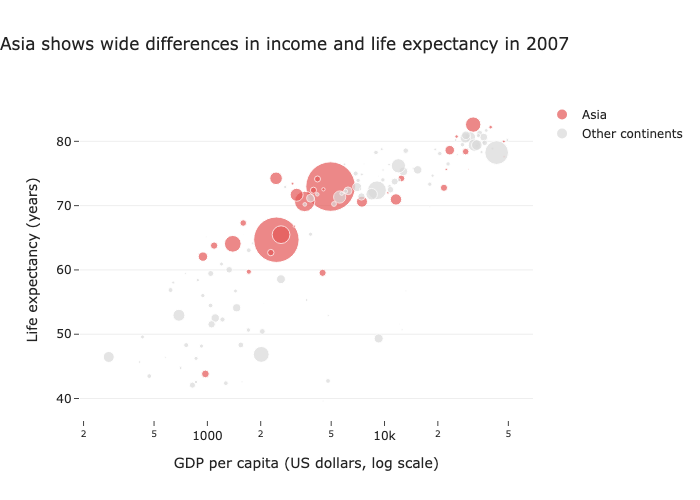

In [4]:
# Task 2
data_2007 = df.loc[df["year"] == 2007].copy()

highlight_continent = "Asia"

data_2007["group"] = data_2007["continent"].apply(
    lambda continent: (
        "Asia" if continent == highlight_continent else "Other continents"
    )
)

fig = px.scatter(
    data_2007,
    x="gdpPercap",
    y="lifeExp",
    size="pop",
    size_max=35,
    color="group",
    color_discrete_map={
        "Asia": "#E45756",
        "Other continents": "#D9D9D9"
    },
    hover_name="country",
    hover_data={
        "continent": True,
        "gdpPercap": ":,.0f",
        "lifeExp": ":.1f",
        "pop": ":,.0f"
    },
    log_x=True,
    title="Asia shows wide differences in income and life expectancy in 2007",
    labels={
        "gdpPercap": "GDP per capita (US dollars, log scale)",
        "lifeExp": "Life expectancy (years)",
        "pop": "Population",
        "group": "Continent"
    }
)

# Annotation explaining the highlighted group's story
fig.add_annotation(
    x=1500,
    y=72,
    text="Asia spans a wide range<br>of income and life expectancy",
    showarrow=True,
    arrowhead=2,
    ax=70,
    ay=-45,
    bgcolor="white",
    bordercolor="#E45756",
    borderwidth=1
)

fig.update_layout(
    template="simple_white",
    title_x=0,
    xaxis=dict(showgrid=False, showline=False),
    yaxis=dict(showgrid=True, gridcolor="#EEEEEE", showline=False),
    legend_title_text=""
)

fig.show(renderer="png")
 